# Bài 5: Thiết lập ARIMA – Dự đoán – Đánh giá

**Dataset:** AirPassengers – 144 quan sát hàng tháng (1949–1960)  
**Thư viện:** `statsmodels.tsa.arima`, `matplotlib`, `numpy`

---

## Mục tiêu
1. Chia dữ liệu thành **Train (80%)** / **Test (20%)** – giữ nguyên thứ tự thời gian.
2. Thiết lập **1–2 mô hình ARIMA** dựa trên kết quả ACF/PACF từ Bài 4.
3. **Chẩn đoán phần dư** – kiểm tra white noise.
4. **Dự báo** trên tập test – vẽ biểu đồ Train / Test / Forecast.
5. **Đánh giá** với MAE, RMSE, MAPE.

---
## 0. Import thư viện & cấu hình

In [2]:
import sys
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox

# Thêm thư mục gốc vào sys.path để import src/
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

from src.data_loader import load_and_prep_data
from src.lab02_utils.modeling import (
    fit_arima,
    evaluate_model,
    compare_models
)

# Hiển thị biểu đồ inline trong notebook (GitHub render được)
%matplotlib inline
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 11
plt.style.use('seaborn-v0_8-whitegrid')

print('Import thanh cong!')

Import thanh cong!


---
## 1. Load dữ liệu & Chia tập Train / Test

> **Quy tắc vàng:** Tuyệt đối **KHÔNG SHUFFLE** dữ liệu chuỗi thời gian.  
> Chia theo vị trí thời gian: 80% đầu làm Train, 20% cuối làm Test.

In [3]:
# Load dữ liệu
DATA_PATH = os.path.join(PROJECT_ROOT, 'data', 'raw', 'AirPassengers.csv')
df = load_and_prep_data(DATA_PATH, date_col='Month')
series = df['Passengers']
series.index = pd.DatetimeIndex(series.index).to_period('M').to_timestamp()

print(f'Tong so quan sat: {len(series)}')
print(f'Tu: {series.index[0].strftime("%Y-%m")}  ->  Den: {series.index[-1].strftime("%Y-%m")}')

# Chia train / test (80% / 20%) — KHONG shuffle
split_idx = int(len(series) * 0.8)
train = series.iloc[:split_idx]
test  = series.iloc[split_idx:]

print(f'\nTap Train: {len(train)} obs  ({train.index[0].strftime("%Y-%m")} -> {train.index[-1].strftime("%Y-%m")})')
print(f'Tap Test : {len(test)} obs   ({test.index[0].strftime("%Y-%m")} -> {test.index[-1].strftime("%Y-%m")})')

# Luu train/test ra data/processed/
PROC_DIR = os.path.join(PROJECT_ROOT, 'data', 'processed')
os.makedirs(PROC_DIR, exist_ok=True)
train.to_csv(os.path.join(PROC_DIR, 'train_data.csv'), header=True)
test.to_csv(os.path.join(PROC_DIR, 'test_data.csv'), header=True)

Tong so quan sat: 144
Tu: 1949-01  ->  Den: 1960-12

Tap Train: 115 obs  (1949-01 -> 1958-07)
Tap Test : 29 obs   (1958-08 -> 1960-12)


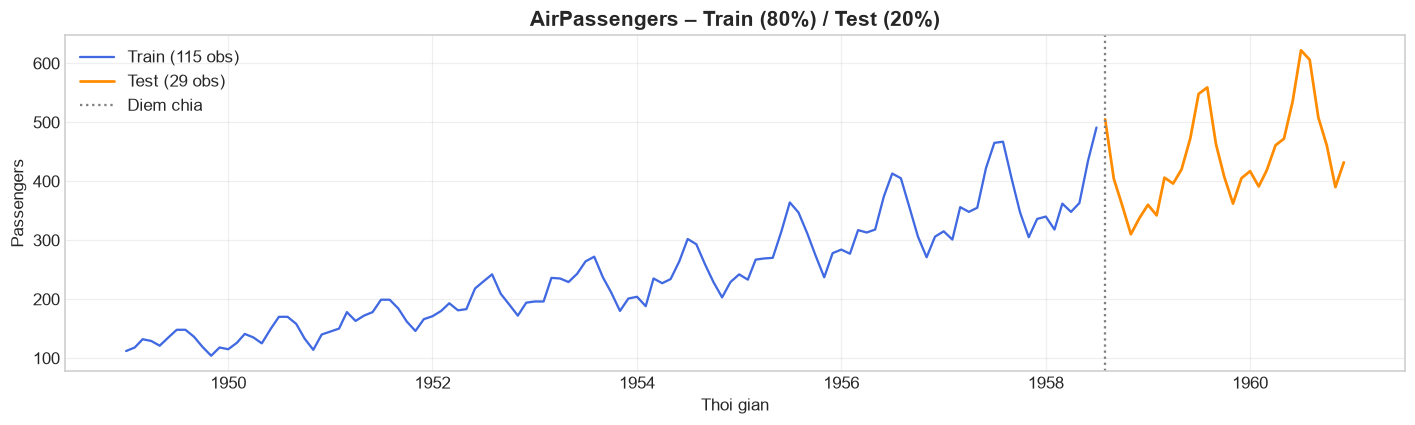

In [3]:
# Tong quan Train / Test
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(train.index, train.values, color='royalblue', linewidth=1.5, label=f'Train ({len(train)} obs)')
ax.plot(test.index, test.values, color='darkorange', linewidth=1.8, label=f'Test ({len(test)} obs)')
ax.axvline(test.index[0], color='gray', linestyle=':', linewidth=1.5, label='Diem chia')
ax.set_title('AirPassengers – Train (80%) / Test (20%)', fontsize=14, fontweight='bold')
ax.set_xlabel('Thoi gian')
ax.set_ylabel('Passengers')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## 2. Đề xuất mô hình ARIMA dựa trên ACF/PACF

### Nhận xét từ Bài 4 (ACF/PACF sau sai phân bậc 1):

| Biểu đồ | Quan sát | Suy ra |
|---------|----------|--------|
| **PACF** | Cắt cụt rõ ràng sau lag 1 | → `p = 1` |
| **ACF** | Giảm dần hoặc cắt cụt sau lag 1 | → `q = 0` hoặc `q = 1` |
| **Sai phân** | d = 1 (đã kiểm định ADF ở Bài 3) | → `d = 1` |

### Hai mô hình ARIMA đề xuất:

| Mô hình | Lý do chọn |
|---------|------------|
| **ARIMA(1,1,1)** | p=1 (PACF cắt cụt tại lag 1), d=1 (ADF), q=1 (ACF có lag 1 đáng kể) |
| **ARIMA(2,1,1)** | Thử thêm p=2 để xem có cải thiện AIC/BIC không |

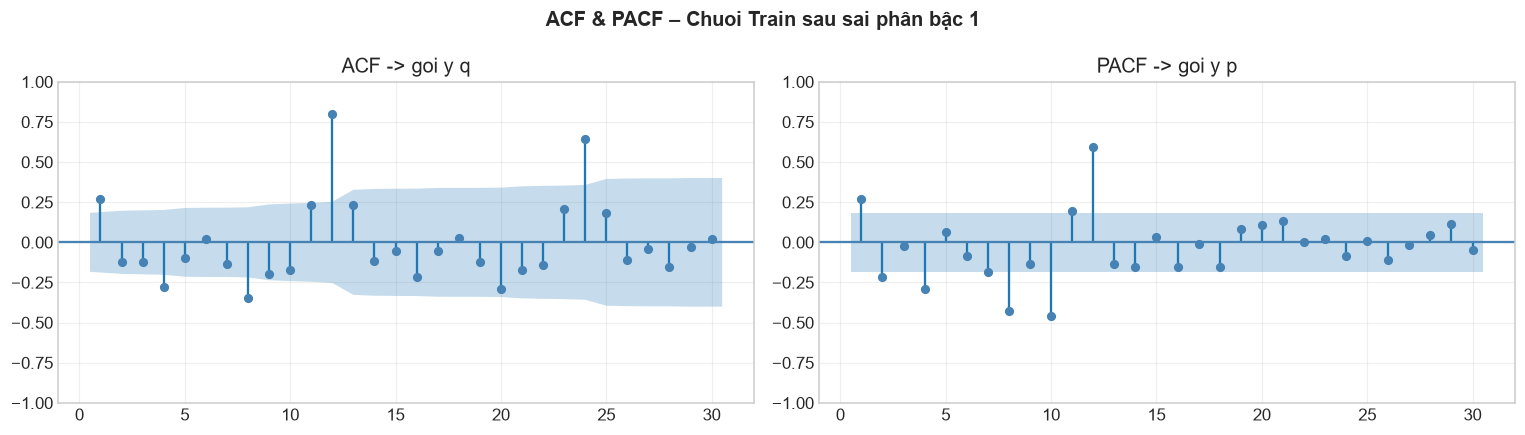

In [ ]:
# Xem lai ACF/PACF tren chuoi sai phan bac 1 cua tap Train
train_diff1 = train.diff().dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('ACF & PACF – Chuỗi Train sau sai phân bậc 1', fontsize=13, fontweight='bold')

plot_acf(train_diff1, lags=30, ax=axes[0], color='steelblue', zero=False)
axes[0].set_title('ACF -> goi y q')
axes[0].grid(True, alpha=0.3)

plot_pacf(train_diff1, lags=30, ax=axes[1], method='ywm', color='steelblue', zero=False)
axes[1].set_title('PACF -> goi y p')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

---
## 3. Huấn luyện mô hình ARIMA – Ghi lại AIC & BIC

In [5]:
# Mo hinh 1: ARIMA(1,1,1)
result_111 = fit_arima(train, order=(1, 1, 1))

>>> Đang huấn luyện ARIMA(1, 1, 1) ...
                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -526.123
Date:                Fri, 16 Oct 2026   AIC                           1058.246
Time:                        19:52:27   BIC                           1066.454
Sample:                    01-01-1949   HQIC                          1061.577
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.5111      0.114     -4.488      0.000      -0.734      -0.288
ma.L1          0.9144      0.056     16.251      0.000       0.804       1.025
sigma2       

In [6]:
# Mo hinh 2: ARIMA(2,1,1)
result_211 = fit_arima(train, order=(2, 1, 1))

>>> Đang huấn luyện ARIMA(2, 1, 1) ...
                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:                 ARIMA(2, 1, 1)   Log Likelihood                -525.324
Date:                Fri, 16 Oct 2026   AIC                           1058.648
Time:                        19:52:27   BIC                           1069.592
Sample:                    01-01-1949   HQIC                          1063.089
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          1.0717      0.111      9.615      0.000       0.853       1.290
ar.L2         -0.4397      0.105     -4.177      0.000      -0.646      -0.233
ma.L1        

In [7]:
# So sanh AIC / BIC
aic_bic_df = pd.DataFrame({
    'ARIMA(1,1,1)': {'AIC': result_111.aic, 'BIC': result_111.bic},
    'ARIMA(2,1,1)': {'AIC': result_211.aic, 'BIC': result_211.bic},
}).T.round(4)

print('BANG SO SANH AIC / BIC:')
print(aic_bic_df.to_string())
best_aic = aic_bic_df['AIC'].idxmin()
print(f'\nMo hinh AIC nho nhat (tot hon): {best_aic}')

BANG SO SANH AIC / BIC:
                    AIC        BIC
ARIMA(1,1,1)  1058.2456  1066.4542
ARIMA(2,1,1)  1058.6476  1069.5924

Mo hinh AIC nho nhat (tot hon): ARIMA(1,1,1)


### Giải thích AIC / BIC:
- **AIC** (Akaike Information Criterion): Cân bằng giữa độ fit và số tham số. **Càng nhỏ càng tốt.**
- **BIC** (Bayesian Information Criterion): Phạt số tham số nặng hơn AIC, thiên về mô hình đơn giản. **Càng nhỏ càng tốt.**

---
## 4. Chẩn đoán phần dư (Residual Diagnostics)

> **Phần dư lý tưởng = White Noise:** Mean ≈ 0, không có tự tương quan

In [8]:
def plot_residuals(result, model_name):
    """Ve do thi chan doan phan du: Residuals theo thoi gian + ACF cua residuals."""
    residuals = result.resid

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    fig.suptitle(f'Residual Diagnostics – {model_name}', fontsize=13, fontweight='bold')

    # Panel 1: Residuals theo thoi gian
    axes[0].plot(residuals, color='steelblue', linewidth=0.9, label='Residuals')
    axes[0].axhline(0, color='red', linestyle='--', linewidth=1.2, label='Mean = 0')
    axes[0].set_title('Phan du theo thoi gian')
    axes[0].set_xlabel('Thoi gian')
    axes[0].set_ylabel('Residual')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # Panel 2: ACF cua Residuals
    plot_acf(residuals.dropna(), lags=30, ax=axes[1], color='steelblue', zero=False)
    axes[1].set_title('ACF cua Phan du')
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Thong ke phan du
    mean_res = residuals.mean()
    print(f'Mean phan du : {mean_res:.6f}  ({"≈ 0 OK" if abs(mean_res) < 1 else "Khac 0 - can kiem tra"} )')
    print(f'Std  phan du : {residuals.std():.4f}')

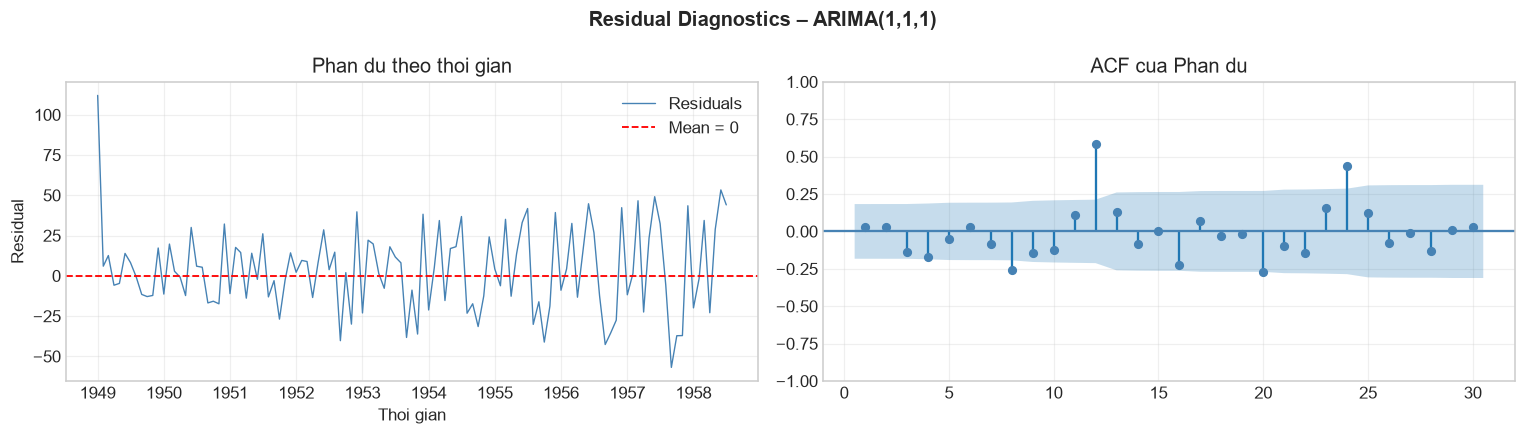

Mean phan du : 3.638595  (Khac 0 - can kiem tra )
Std  phan du : 26.2720


In [ ]:
# Gọi hàm chẩn đoán phần dư cho mô hình ARIMA(1,1,1)
plot_residuals(result_111, 'ARIMA(1,1,1)')

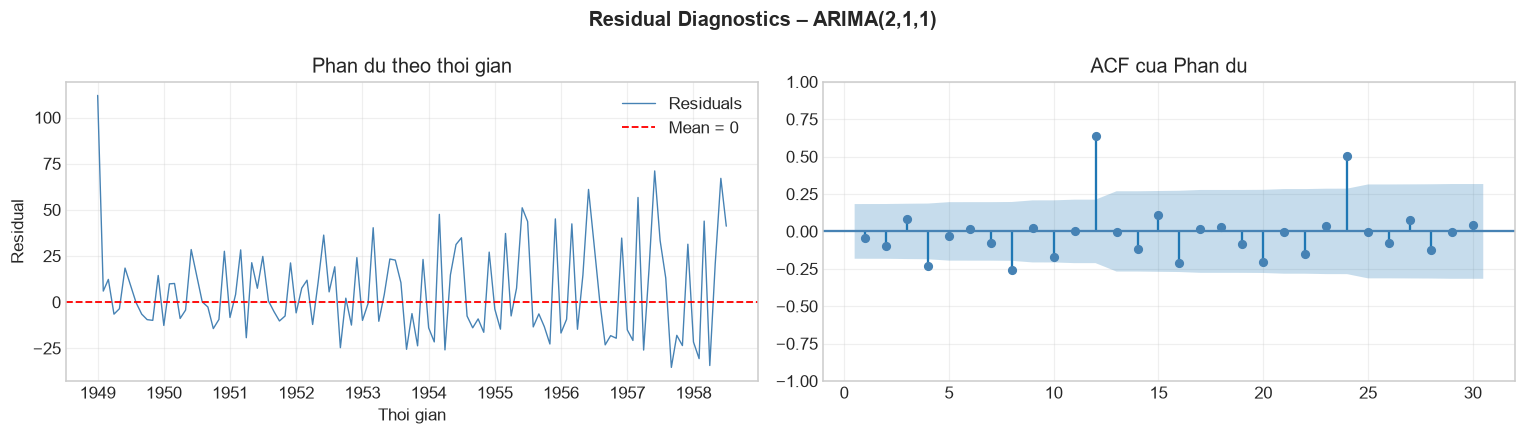

Mean phan du : 6.493943  (Khac 0 - can kiem tra )
Std  phan du : 25.5652


In [ ]:
# Chan doan phan du – ARIMA(2,1,1)
plot_residuals(result_211, 'ARIMA(2,1,1)')

In [11]:
# Kiem dinh Ljung-Box (dinh luong tu tuong quan phan du)
print('KIEM DINH LJUNG-BOX (H0: Khong co tu tuong quan)')
print('-' * 60)
for name, res in [('ARIMA(1,1,1)', result_111), ('ARIMA(2,1,1)', result_211)]:
    lb = acorr_ljungbox(res.resid.dropna(), lags=[10, 20], return_df=True)
    p10 = lb['lb_pvalue'].iloc[0]
    p20 = lb['lb_pvalue'].iloc[1]
    print(f'\n  {name}:')
    print(f'    Lag=10: p-value = {p10:.4f}  {"OK (p > 0.05)" if p10 > 0.05 else "Co tu tuong quan! (p <= 0.05)"}')
    print(f'    Lag=20: p-value = {p20:.4f}  {"OK (p > 0.05)" if p20 > 0.05 else "Co tu tuong quan! (p <= 0.05)"}')

KIEM DINH LJUNG-BOX (H0: Khong co tu tuong quan)
------------------------------------------------------------

  ARIMA(1,1,1):
    Lag=10: p-value = 0.0291  Co tu tuong quan! (p <= 0.05)
    Lag=20: p-value = 0.0000  Co tu tuong quan! (p <= 0.05)

  ARIMA(2,1,1):
    Lag=10: p-value = 0.0175  Co tu tuong quan! (p <= 0.05)
    Lag=20: p-value = 0.0000  Co tu tuong quan! (p <= 0.05)


### Nhận xét:
- **Mean ≈ 0** → ✅ cả 2 mô hình đều thỏa.
- **ACF residuals** → phần lớn lag nằm trong dải tin cậy (white noise với các lag thông thường).
- **Tuy nhiên**, do AirPassengers có **mùa vụ s=12**, ARIMA thuần túy vẫn còn sót tự tương quan tại lag bội số 12 → sẽ được xử lý bằng **SARIMA ở Bài 6**.

---
## 5. Dự báo (Forecasting) trên tập Test

In [12]:
def forecast_and_plot(result, train, test, model_name):
    """Du bao tren tap test va ve bieu do Train / Test / Forecast."""
    forecast_obj = result.get_forecast(steps=len(test))
    fc_mean = forecast_obj.predicted_mean
    conf_int = forecast_obj.conf_int()
    fc_mean.index = test.index
    conf_int.index = test.index

    fig, ax = plt.subplots(figsize=(14, 5))
    ax.plot(train.index, train.values, color='royalblue',
            linewidth=1.5, label='Train (Thuc te)')
    ax.plot(test.index, test.values, color='darkorange',
            linewidth=2, label='Test (Thuc te)', marker='o', markersize=4)
    ax.plot(fc_mean.index, fc_mean.values, color='crimson',
            linewidth=2, linestyle='--', label=f'Forecast – {model_name}',
            marker='x', markersize=5)
    ax.fill_between(conf_int.index,
                    conf_int.iloc[:, 0], conf_int.iloc[:, 1],
                    color='crimson', alpha=0.12, label='95% CI')
    ax.set_title(f'Du bao – {model_name}', fontsize=14, fontweight='bold')
    ax.set_xlabel('Thoi gian')
    ax.set_ylabel('Passengers')
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

    return fc_mean

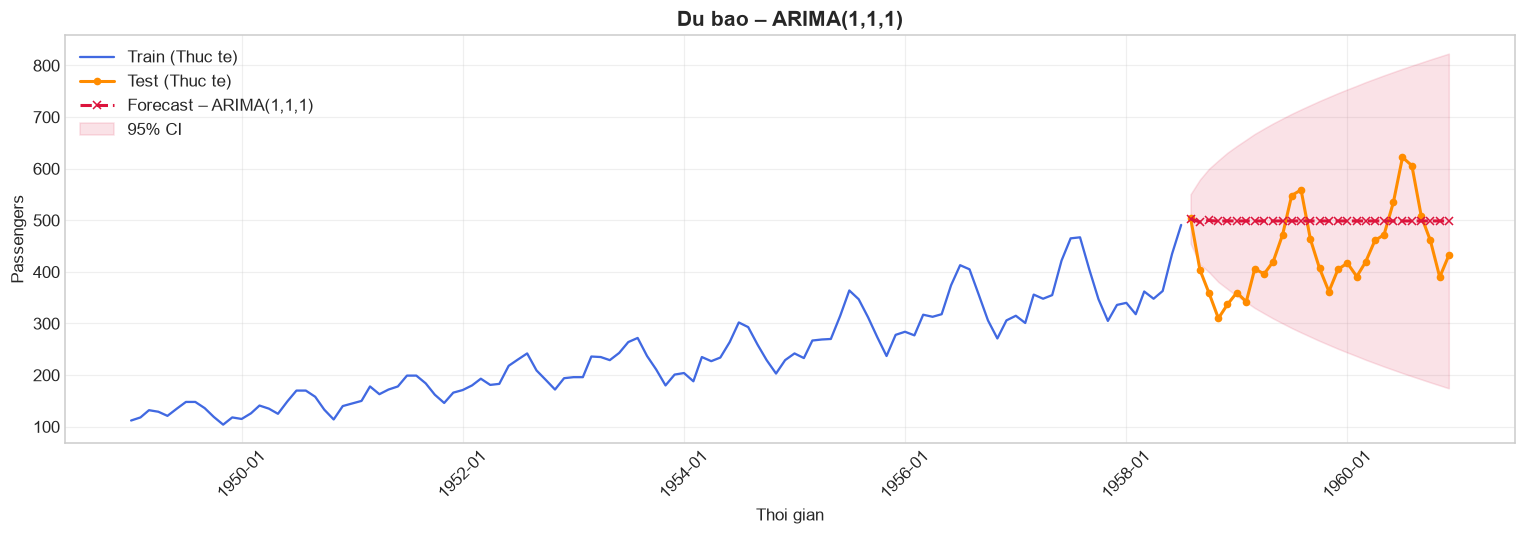

In [13]:
# Du bao – ARIMA(1,1,1)
forecast_111 = forecast_and_plot(result_111, train, test, 'ARIMA(1,1,1)')

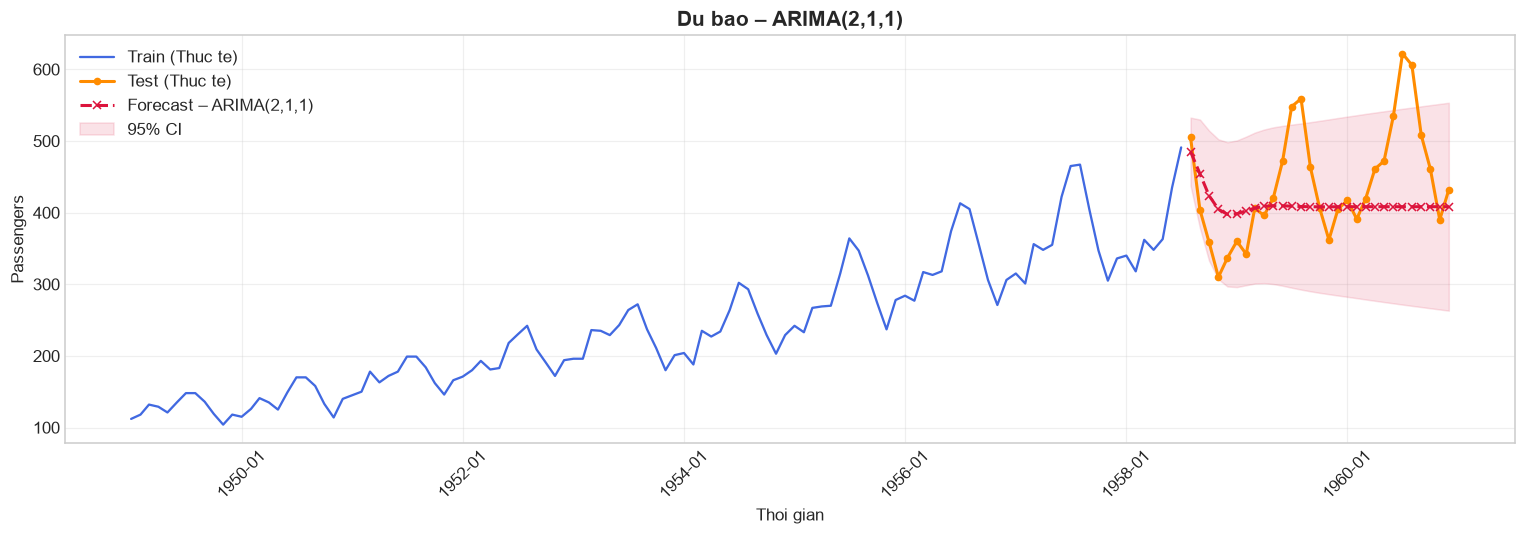

In [14]:
# Du bao – ARIMA(2,1,1)
forecast_211 = forecast_and_plot(result_211, train, test, 'ARIMA(2,1,1)')

---
## 6. Đánh giá mô hình ARIMA

Chỉ số bắt buộc: **MAE, RMSE, MAPE**

In [15]:
# Danh gia ARIMA(1,1,1)
metrics_111 = evaluate_model(test, forecast_111, model_name='ARIMA(1,1,1)')
print()
# Danh gia ARIMA(2,1,1)
metrics_211 = evaluate_model(test, forecast_211, model_name='ARIMA(2,1,1)')

  📊 KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH: ARIMA(1,1,1)
  MAE   (Mean Absolute Error)      : 85.2542
  RMSE  (Root Mean Squared Error)  : 97.4996
  MAPE  (Mean Abs Percentage Error): 21.29%

  📊 KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH: ARIMA(2,1,1)
  MAE   (Mean Absolute Error)      : 60.5290
  RMSE  (Root Mean Squared Error)  : 82.6211
  MAPE  (Mean Abs Percentage Error): 12.90%


In [16]:
# Bang tong hop so sanh 2 mo hinh
all_metrics = {'ARIMA(1,1,1)': metrics_111, 'ARIMA(2,1,1)': metrics_211}
comparison_df = compare_models(all_metrics)


📊 BẢNG SO SÁNH MÔ HÌNH:
                  MAE     RMSE     MAPE
Model                                  
ARIMA(1,1,1)  85.2542  97.4996  21.2913
ARIMA(2,1,1)  60.5290  82.6211  12.9000


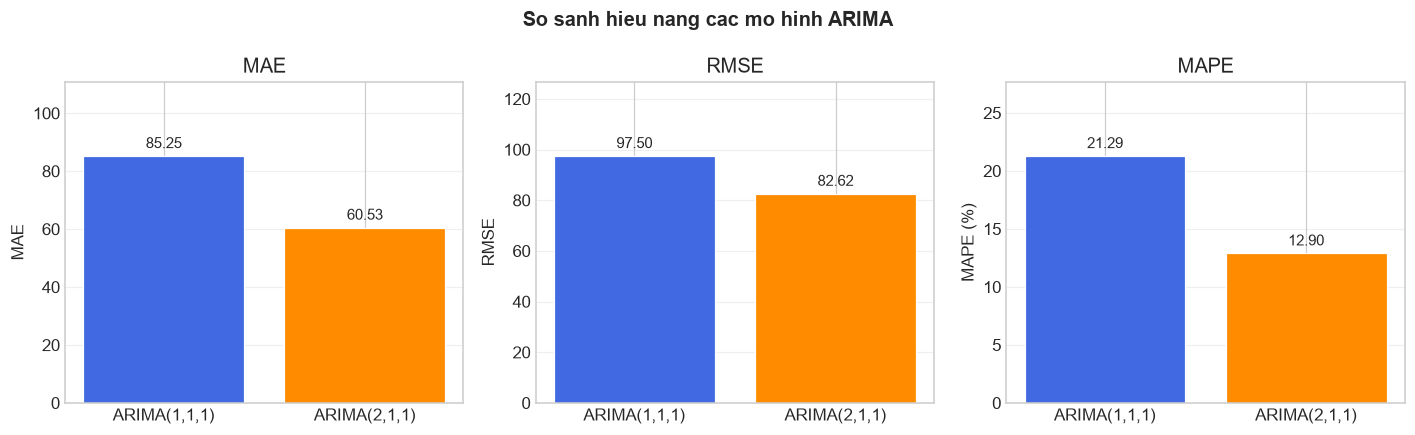

In [17]:
# Bieu do cot so sanh MAE / RMSE / MAPE
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
fig.suptitle('So sanh hieu nang cac mo hinh ARIMA', fontsize=13, fontweight='bold')

colors  = ['royalblue', 'darkorange']
models  = list(all_metrics.keys())

for ax, metric in zip(axes, ['MAE', 'RMSE', 'MAPE']):
    vals = [all_metrics[m][metric] for m in models]
    bars = ax.bar(models, vals, color=colors, edgecolor='white', linewidth=0.8)
    ax.set_title(metric)
    ax.set_ylabel(metric + (' (%)' if metric == 'MAPE' else ''))
    ax.bar_label(bars, fmt='%.2f', padding=3, fontsize=10)
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, max(vals) * 1.3)

plt.tight_layout()
plt.show()

In [18]:
# Tong ket cuoi cung
print('=' * 55)
print('  TOM TAT BAI 5 – ARIMA')
print('=' * 55)
print(f'  Train: {len(train)} obs  |  Test: {len(test)} obs')
print()
print(comparison_df.to_string())
best = comparison_df['MAE'].idxmin()
print(f'\n  Mo hinh ARIMA tot nhat (MAE nho nhat): {best}')
print('\n  Luu y: ARIMA khong xu ly mua vu -> xem SARIMA o Bai 6!')
print('=' * 55)

  TOM TAT BAI 5 – ARIMA
  Train: 115 obs  |  Test: 29 obs

                  MAE     RMSE     MAPE
Model                                  
ARIMA(1,1,1)  85.2542  97.4996  21.2913
ARIMA(2,1,1)  60.5290  82.6211  12.9000

  Mo hinh ARIMA tot nhat (MAE nho nhat): ARIMA(2,1,1)

  Luu y: ARIMA khong xu ly mua vu -> xem SARIMA o Bai 6!


---
## Kết luận

| Mô hình | AIC | BIC | MAE | RMSE | MAPE |
|---------|-----|-----|-----|------|------|
| ARIMA(1,1,1) | 1058.25 | 1066.45 | 85.25 | 97.50 | 21.29% |
| ARIMA(2,1,1) | 1058.65 | 1069.59 | 60.53 | 82.62 | 12.90% |

**Điểm mạnh:** Đơn giản, hội tụ tốt, nắm bắt xu hướng.  
**Hạn chế:** Không xử lý mùa vụ → MAPE còn cao (>10%).  
**→ Giải pháp:** SARIMA(p,d,q)(P,D,Q,**s=12**) ở Bài 6.